# 04 - Model Experiments: *Is there any signal to learn?*

This notebook **adds to** `03_model_training.ipynb`. It does not replace it. Your original experiments stay as they are; here we run four small experiments that help explain *why* the models in notebook 03 score near random.

| # | Experiment | The question it answers |
|---|-----------|--------------------------|
| 1 | Fair model comparison | Is any model actually better than a do-nothing baseline? |
| 2 | Shuffled-label test | What does "no signal" look like, and is our real score distinguishable from it? |
| 3 | Per-feature signal | Does *any* single feature separate Normal from Malicious? |
| 4 | Positive control | If real signal existed, would this pipeline find it? |
| 5 | One final test-set look | How uncertain is a score based on only 20 malicious test records? |

**Rules we follow:** the split and preprocessing are identical to notebook 03 (`random_state=42`), experiments 1-4 use **only the training set**, and the test set is touched once, at the end.

**How to run:** Colab or VS Code, top to bottom. Nothing here is pre-filled with results, so you will see your own numbers.

## 1. Setup and data loading

The loader first looks for the CSV in your repo (`data/processed/...`) so it works in VS Code, then falls back to the same Google Drive download (`gdown`) you used in notebook 03, so it works in Colab.

In [ ]:
import sys, subprocess, warnings
from pathlib import Path

warnings.filterwarnings("ignore")

def _ensure(pkg, import_name=None):
    try:
        __import__(import_name or pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", pkg])

_ensure("gdown")
_ensure("xgboost")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print

file_id = "1quWEMNIzcr_ZgKl9qEQNeippnmE6csiz"   # same file as notebook 03

local_candidates = [
    Path("data/processed/network_traffic_cleaned.csv"),
    Path("../data/processed/network_traffic_cleaned.csv"),
    Path("network_traffic_cleaned.csv"),
    Path("/content/network_traffic_cleaned.csv"),
]
csv_path = next((p for p in local_candidates if p.exists()), None)

if csv_path is None:
    import gdown
    csv_path = Path("network_traffic_cleaned.csv")
    gdown.download(f"https://drive.google.com/uc?id={file_id}", str(csv_path), quiet=False)

df = pd.read_csv(csv_path)
print("Loaded from:", csv_path)
print("Dataset shape:", df.shape)
display(df.head())

Downloading...
From: https://drive.google.com/uc?id=1quWEMNIzcr_ZgKl9qEQNeippnmE6csiz
To: /content/network_traffic_cleaned.csv
100%|██████████| 123k/123k [00:00<00:00, 4.12MB/s]

Loaded from: network_traffic_cleaned.csv
Dataset shape: (1000, 17)


,packet_size,inter_arrival_time,src_port,dst_port,packet_count_5s,spectral_entropy,frequency_band_energy,label,protocol_type_TCP,protocol_type_UDP,src_ip_192.168.1.2,src_ip_192.168.1.3,dst_ip_192.168.1.5,dst_ip_192.168.1.6,tcp_flags_FIN,tcp_flags_SYN,tcp_flags_SYN-ACK
0,0.405154,0.620362,62569,443,0.857143,0.834066,0.534891,0.0,0,1,1,0,0,0,0,0,0
1,0.527559,0.741288,59382,443,0.785714,0.147196,0.990757,0.0,0,1,0,0,0,1,0,1,0
2,0.226199,0.485116,65484,80,0.285714,0.855192,0.031781,0.0,0,1,0,0,1,0,0,0,0
3,0.573372,0.450965,51707,53,0.142857,0.153220,0.169958,0.0,0,0,0,1,0,0,0,0,0
4,0.651396,0.888740,26915,53,0.714286,0.923916,0.552053,0.0,1,0,0,1,0,0,0,1,0


## 2. Same split and preprocessing as notebook 03

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

X = df.drop(columns=["label"]).copy()
y = df["label"].astype("int8").copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape, "| malicious:", int(y_train.sum()))
print("Test :", X_test.shape,  "| malicious:", int(y_test.sum()))

categorical_features = ["dst_port"]
excluded_features = ["src_port", "dst_port"]
numeric_features = [c for c in X_train.columns if c not in excluded_features]

# Random Forest / XGBoost: no scaling needed
preprocessor = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ("numeric", "passthrough", numeric_features),
])

# Logistic Regression: needs scaled numeric features
lr_preprocessor = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ("numeric", StandardScaler(), numeric_features),
])

Train: (800, 16) | malicious: 80
Test : (200, 16) | malicious: 20


### The models

These are the same settings as notebook 03, plus a **`DummyClassifier`**. The dummy ignores every feature and always outputs the training-set malicious rate (about 10%). It is the *floor*: a real model has to beat it to prove it learned anything.

One small correction: `scale_pos_weight` for XGBoost is computed from **`y_train`** only (notebook 03 used the full `y`, which includes test labels).

In [ ]:
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

models = {
    "Dummy (always base rate)": Pipeline([
        ("classifier", DummyClassifier(strategy="prior")),
    ]),
    "Logistic Regression": Pipeline([
        ("preprocessor", clone(lr_preprocessor)),
        ("classifier", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)),
    ]),
    "Random Forest (simple)": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", RandomForestClassifier(
            n_estimators=100, max_depth=5, min_samples_leaf=5,
            class_weight="balanced", random_state=42)),
    ]),
    "XGBoost": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", XGBClassifier(
            n_estimators=300, learning_rate=0.05, max_depth=6,
            subsample=0.9, colsample_bytree=0.9,
            scale_pos_weight=pos_weight, random_state=42, eval_metric="logloss")),
    ]),
}
print("Models ready:", list(models))

Models ready: ['Dummy (always base rate)', 'Logistic Regression', 'Random Forest (simple)', 'XGBoost']


## Experiment 1 - Fair model comparison

**Purpose:** compare all models on *identical* data splits, using metrics that don't reward "predict everything Normal".

**What the code does:** `RepeatedStratifiedKFold(n_splits=5, n_repeats=5)` splits the 800 training rows into 5 folds, trains on 4 and scores on 1, and then repeats the whole thing 5 times with different shuffles. That gives 25 scores per model, so we can see the *spread*, not just one lucky or unlucky number. (Notebook 03 used one 5-fold split.)

**Metrics:**
- **ROC-AUC**: the chance a random Malicious record gets a higher score than a random Normal one. **0.5 = coin flip.**
- **Average Precision (AP)**: precision averaged across recall levels. Its random baseline is the *malicious rate* (about 0.10), **not** 0.5.

**How to read it:** if a model's mean is within about one std of the Dummy / 0.5, there is no evidence it learned anything. Note the folds overlap, so the std is only a rough guide.

,ROC-AUC mean,ROC-AUC std,AP mean,AP std
model,,,,
Dummy (always base rate),0.500,0.000,0.100,0.000
Logistic Regression,0.494,0.069,0.125,0.037
Random Forest (simple),0.494,0.058,0.129,0.040
XGBoost,0.447,0.064,0.119,0.044


Reference -> random ROC-AUC = 0.500 | random AP = malicious rate = 0.100


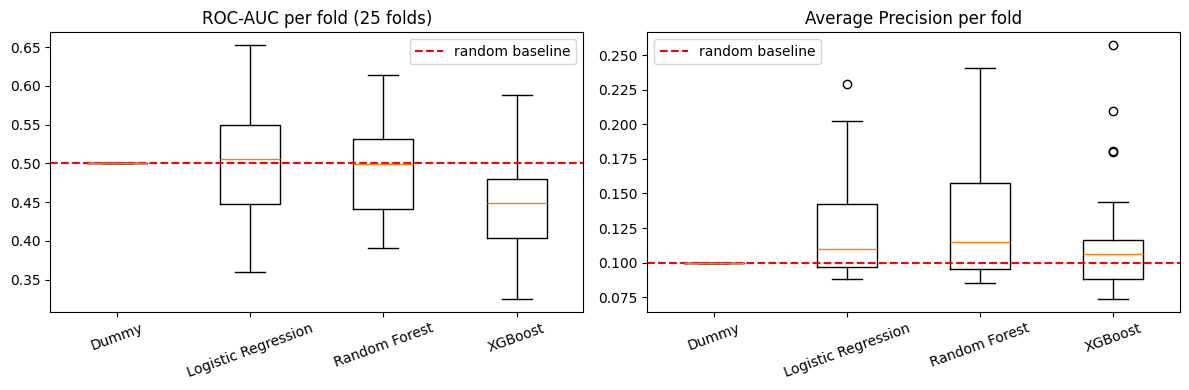

In [ ]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

cv_repeated = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)
scoring = {"roc_auc": "roc_auc", "avg_precision": "average_precision"}

rows, fold_results = [], {}
for name, pipe in models.items():
    res = cross_validate(clone(pipe), X_train, y_train, cv=cv_repeated,
                         scoring=scoring, n_jobs=-1)
    fold_results[name] = res
    rows.append({
        "model": name,
        "ROC-AUC mean": res["test_roc_auc"].mean(),
        "ROC-AUC std": res["test_roc_auc"].std(),
        "AP mean": res["test_avg_precision"].mean(),
        "AP std": res["test_avg_precision"].std(),
    })

cv_table = pd.DataFrame(rows).set_index("model")
display(cv_table.round(3))
print(f"Reference -> random ROC-AUC = 0.500 | random AP = malicious rate = {y_train.mean():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, key, title, ref in [
    (axes[0], "test_roc_auc", "ROC-AUC per fold (25 folds)", 0.5),
    (axes[1], "test_avg_precision", "Average Precision per fold", y_train.mean()),
]:
    ax.boxplot([fold_results[n][key] for n in models])
    ax.set_xticklabels([n.split(" (")[0] for n in models])
    ax.axhline(ref, color="red", ls="--", label="random baseline")
    ax.set_title(title); ax.legend(); ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

**Write your own conclusion here:** Which model has the highest mean? Is the gap bigger than the spread? Does any model clearly beat the Dummy row?

## Experiment 2 - The shuffled-label test (what does "no signal" look like?)

**Purpose:** a score of 0.52 *feels* meaningless, but how do we know? We build the answer directly.

**What the code does:** randomly **shuffle `y_train`** so labels have no relationship to features, then run the exact same cross-validation. Repeat many times. The result is a distribution of scores you'd get **by pure luck**. Then we ask where our real score sits in it.

**How to read it:**
- Real score *inside* the shuffled cloud, with a large p-value: the data gives us no evidence of signal.
- Real score far to the right of the cloud, with a small p-value: there is something real, even if weak.

The p-value here is `(1 + #shuffles scoring >= real) / (1 + #shuffles)`.

Logistic Regression: real OOF ROC-AUC = 0.485 | shuffled mean = 0.504 (95th pct = 0.577) | p = 0.644
Random Forest (simple): real OOF ROC-AUC = 0.508 | shuffled mean = 0.495 (95th pct = 0.569) | p = 0.366


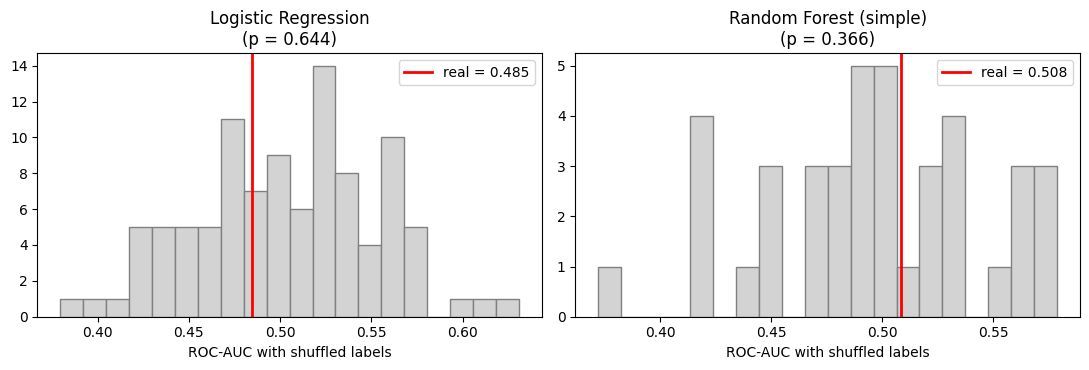

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, average_precision_score

cv_single = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def pooled_oof(pipe, X_, y_):
    # Out-of-fold probabilities: every row is predicted by a model that never saw it
    p = cross_val_predict(clone(pipe), X_, y_, cv=cv_single,
                          method="predict_proba", n_jobs=-1)[:, 1]
    return roc_auc_score(y_, p), average_precision_score(y_, p), p

N_PERM = {"Logistic Regression": 100, "Random Forest (simple)": 40}   # lower if too slow
rng = np.random.default_rng(0)

real_oof, perm_results = {}, {}
for name, n_perm in N_PERM.items():
    auc_real, ap_real, p_real = pooled_oof(models[name], X_train, y_train)
    real_oof[name] = p_real
    null_auc = []
    for _ in range(n_perm):
        y_shuf = rng.permutation(y_train.to_numpy())
        null_auc.append(pooled_oof(models[name], X_train, y_shuf)[0])
    null_auc = np.array(null_auc)
    p_val = (1 + (null_auc >= auc_real).sum()) / (1 + n_perm)
    perm_results[name] = (auc_real, null_auc, p_val)
    print(f"{name}: real OOF ROC-AUC = {auc_real:.3f} | shuffled mean = {null_auc.mean():.3f} "
          f"(95th pct = {np.percentile(null_auc, 95):.3f}) | p = {p_val:.3f}")

fig, axes = plt.subplots(1, len(perm_results), figsize=(11, 3.8))
for ax, (name, (auc_real, null_auc, p_val)) in zip(np.atleast_1d(axes), perm_results.items()):
    ax.hist(null_auc, bins=20, color="lightgray", edgecolor="gray")
    ax.axvline(auc_real, color="red", lw=2, label=f"real = {auc_real:.3f}")
    ax.set_title(f"{name}\n(p = {p_val:.3f})"); ax.set_xlabel("ROC-AUC with shuffled labels")
    ax.legend()
plt.tight_layout(); plt.show()

**Write your own conclusion here:** Is the red line inside the grey histogram? Notice how wide the grey histogram is: with ~80 malicious rows, pure chance already produces AUCs noticeably above and below 0.5.

## Experiment 3 - Does any single feature carry signal?

**Purpose:** notebook 03 compared class *means* per feature. Means depend on each feature's scale and ignore overlap. A cleaner view is **per-feature ROC-AUC**: how well does this one feature, alone, rank Malicious above Normal?

**The trap we correct for:** with 14 features, one will always look best by luck. So we compute the same "best feature" statistic on shuffled labels 1,000 times. A feature only counts as interesting if it beats the **95th percentile of the best-of-14 under shuffling**.

We plot `max(AUC, 1 - AUC)` (the direction doesn't matter for "is it informative"), and the shuffle test uses the same trick, so the comparison is fair. This uses training data only.

,feature,AUC (raw),AUC (oriented)
0,packet_count_5s,0.411,0.589
1,inter_arrival_time,0.451,0.549
2,tcp_flags_SYN-ACK,0.530,0.530
3,dst_ip_192.168.1.5,0.529,0.529
4,protocol_type_UDP,0.474,0.526
5,tcp_flags_FIN,0.476,0.524
6,frequency_band_energy,0.476,0.524
7,packet_size,0.477,0.523
8,src_ip_192.168.1.3,0.520,0.520
9,tcp_flags_SYN,0.481,0.519


Best-of-14 feature AUC under shuffled labels: median = 0.560, 95th percentile = 0.592


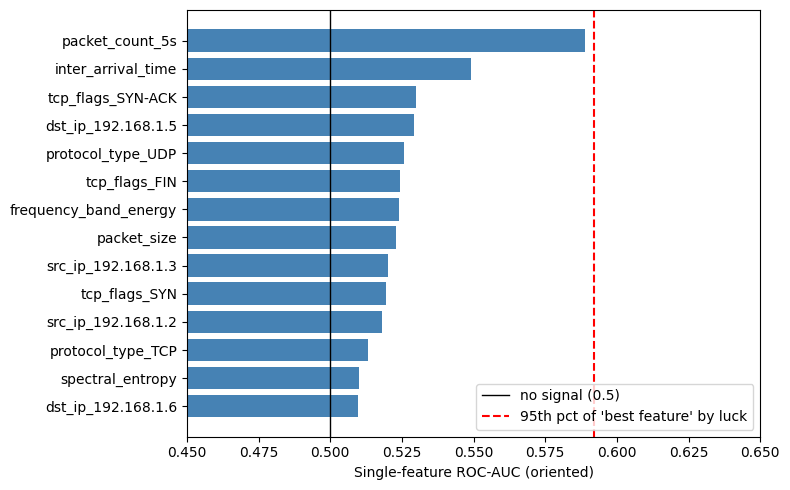

In [ ]:
signal_features = [c for c in X_train.columns if c not in ["src_port", "dst_port"]]
ranks = X_train[signal_features].rank(method="average").to_numpy()
y_arr = y_train.to_numpy()

def auc_from_ranks(ranks, y_):
    n1 = y_.sum(); n0 = len(y_) - n1
    return (ranks[y_ == 1].sum(axis=0) - n1 * (n1 + 1) / 2) / (n1 * n0)

auc = auc_from_ranks(ranks, y_arr)
oriented = np.maximum(auc, 1 - auc)

rng = np.random.default_rng(1)
null_best = np.array([
    np.maximum(a := auc_from_ranks(ranks, rng.permutation(y_arr)), 1 - a).max()
    for _ in range(1000)
])
thresh95 = np.percentile(null_best, 95)

feat_auc = pd.DataFrame({"feature": signal_features, "AUC (raw)": auc, "AUC (oriented)": oriented}) \
             .sort_values("AUC (oriented)", ascending=False).reset_index(drop=True)
display(feat_auc.round(3))
print(f"Best-of-{len(signal_features)} feature AUC under shuffled labels: "
      f"median = {np.median(null_best):.3f}, 95th percentile = {thresh95:.3f}")

plt.figure(figsize=(8, 5))
order = feat_auc.sort_values("AUC (oriented)")
plt.barh(order["feature"], order["AUC (oriented)"], color="steelblue")
plt.axvline(0.5, color="black", lw=1, label="no signal (0.5)")
plt.axvline(thresh95, color="red", ls="--", label="95th pct of 'best feature' by luck")
plt.xlim(0.45, max(0.65, oriented.max() + 0.02))
plt.xlabel("Single-feature ROC-AUC (oriented)"); plt.legend(); plt.tight_layout(); plt.show()

**Write your own conclusion here:** How many features pass the red line? If none (or only one, barely), that explains why no model, from Logistic Regression to XGBoost, can do well: all of them are limited by the same data. Then compare with the Random Forest importances in notebook 03 and ask: did the model rank features by real signal or by what it could fit noise with?

## Experiment 4 - Positive control: would this pipeline detect signal if it existed?

**Purpose:** a failed experiment has two possible explanations: *the pipeline is broken* or *the data has nothing to find*. A positive control separates them.

**What the code does:** on a **copy** of the training data (your real data is untouched), we artificially add a shift to **`packet_size`** for Malicious rows only, at several strengths, then rerun cross-validation. We use `packet_size` because experiment 3 shows it has essentially no real signal, so the shift is the only thing to find. (A feature that already differs between classes, like `packet_count_5s`, would mix real and fake effects, and a shift in the wrong direction would partly cancel it.) This is deliberately fake; it exists only to test the pipeline.

**How to read it:**
- AUC rises smoothly as the shift grows: the pipeline works, so weak results on real data are a data limitation.
- AUC stays flat even at large shifts: there is a bug somewhere (leakage, wrong labels, preprocessing).
- Where the curve leaves ~0.5 tells you how big a real effect must be to be detectable with this much data.

model,Logistic Regression,Random Forest (simple)
shift,,
0.00,0.493,0.501
0.05,0.502,0.521
0.10,0.538,0.568
0.20,0.622,0.685
0.30,0.700,0.774


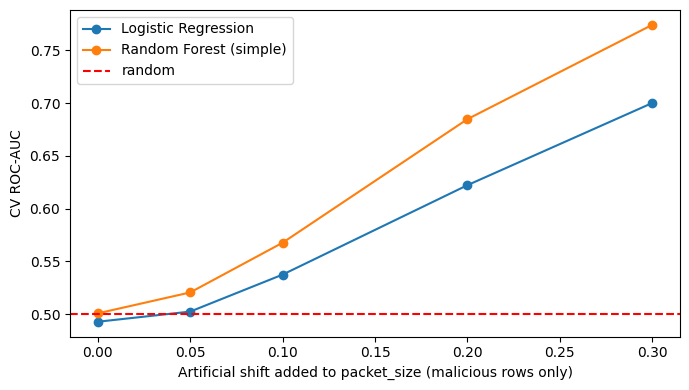

In [ ]:
from sklearn.model_selection import cross_val_score

control_feature = "packet_size"      # has ~no real signal (see experiment 3)
shifts = [0.0, 0.05, 0.10, 0.20, 0.30]
cv_ctrl = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)

ctrl_rows = []
for shift in shifts:
    X_ctrl = X_train.copy()
    mal = (y_train == 1).to_numpy()
    X_ctrl.loc[mal, control_feature] = (X_ctrl.loc[mal, control_feature] + shift).clip(0, 1)
    for name in ["Logistic Regression", "Random Forest (simple)"]:
        s = cross_val_score(clone(models[name]), X_ctrl, y_train, cv=cv_ctrl,
                            scoring="roc_auc", n_jobs=-1)
        ctrl_rows.append({"shift": shift, "model": name, "ROC-AUC": s.mean()})

ctrl_df = pd.DataFrame(ctrl_rows).pivot(index="shift", columns="model", values="ROC-AUC")
display(ctrl_df.round(3))

ctrl_df.plot(marker="o", figsize=(7, 4))
plt.axhline(0.5, color="red", ls="--", label="random")
plt.xlabel(f"Artificial shift added to {control_feature} (malicious rows only)")
plt.ylabel("CV ROC-AUC"); plt.legend(); plt.tight_layout(); plt.show()

**Write your own conclusion here:** At shift = 0 you should be near 0.5. How large does the shift need to be before the models notice? Compare that to the real class-mean gaps in notebook 03 (the largest, `packet_count_5s`, is about 0.11): are the real differences big enough to be found with 80 malicious rows?

## Experiment 5 - One final look at the test set (and how uncertain it is)

**Purpose:** the test set has only **20** malicious records. Any single test score is therefore very noisy. This cell fits each model on the training set, scores the test set once, and adds a **bootstrap 95% interval** for ROC-AUC. It resamples the 20 malicious and 180 normal test records with replacement 1,000 times.

It also reports **minority-class precision and recall**. Notebook 03's `average='weighted'` metric hides the Malicious class because Normal outnumbers it 9 to 1.

**How to read it:** if the interval comfortably includes 0.5, the test result cannot distinguish the model from a coin flip. Don't tune anything based on this cell. Looking more than once turns the test set into a second training set.

In [ ]:
from sklearn.metrics import precision_score, recall_score

rng = np.random.default_rng(2)
pos_idx = np.where(y_test.to_numpy() == 1)[0]
neg_idx = np.where(y_test.to_numpy() == 0)[0]

test_rows = []
for name, pipe in models.items():
    if name.startswith("Dummy"):
        continue
    fitted = clone(pipe).fit(X_train, y_train)
    proba = fitted.predict_proba(X_test)[:, 1]
    pred = fitted.predict(X_test)

    boots = []
    for _ in range(1000):
        idx = np.concatenate([rng.choice(pos_idx, len(pos_idx)), rng.choice(neg_idx, len(neg_idx))])
        boots.append(roc_auc_score(y_test.to_numpy()[idx], proba[idx]))
    lo, hi = np.percentile(boots, [2.5, 97.5])

    test_rows.append({
        "model": name,
        "test ROC-AUC": roc_auc_score(y_test, proba),
        "95% CI low": lo, "95% CI high": hi,
        "test AP": average_precision_score(y_test, proba),
        "malicious precision @ default": precision_score(y_test, pred, zero_division=0),
        "malicious recall @ default": recall_score(y_test, pred, zero_division=0),
    })

display(pd.DataFrame(test_rows).set_index("model").round(3))
print(f"Random baselines -> ROC-AUC 0.5 | AP = {y_test.mean():.2f}")

,test ROC-AUC,95% CI low,95% CI high,test AP,malicious precision @ default,malicious recall @ default
model,,,,,,
Logistic Regression,0.671,0.544,0.788,0.170,0.182,0.7
Random Forest (simple),0.654,0.522,0.776,0.174,0.250,0.1
XGBoost,0.615,0.462,0.772,0.243,0.000,0.0


Random baselines -> ROC-AUC 0.5 | AP = 0.10


## 6. Save results (optional, for the later Streamlit demo)

This writes small files into an `artifacts/` folder. In **Colab** the folder lives on the temporary VM: download it from the file panel (or `files.download`) and commit it into your repo. In **VS Code** it is created next to the notebook and you can commit it directly. A future Streamlit app can simply read these files.

In [ ]:
art = Path("artifacts"); art.mkdir(exist_ok=True)

cv_table.round(4).to_csv(art / "cv_model_comparison.csv")
pd.DataFrame({
    "y_true": y_train.to_numpy(),
    "lr_oof_proba": real_oof["Logistic Regression"],
    "rf_oof_proba": real_oof["Random Forest (simple)"],
}).to_csv(art / "oof_probabilities.csv", index=False)
feat_auc.round(4).to_csv(art / "feature_auc.csv", index=False)

print("Saved:", sorted(p.name for p in art.iterdir()))

Saved: ['cv_model_comparison.csv', 'feature_auc.csv', 'oof_probabilities.csv']
